# Business & revenue (measured)

**Block II — measured.** This notebook describes the **real** feeds: `orders` and `bookings_legs` (the islands) and the clickstream `events` / `sessions`. It is the "measured" half of the lab.

> **Island caveat — read first.** Every number here is **measured**, but two of the four tables are **islands**. `orders` and `bookings_legs` carry **no `user_id` and no foreign key** — not to each other, not to the clickstream. And `orders` (**Nov 2023 – Jan 2024**) does **not overlap in time** with the clickstream (**May 2023**). **No unified end-to-end funnel is possible**, and the two blocks are never fused (see `docs/adr/0001-modeled-vs-measured.md`).

Evidence class for this entire notebook: **measured**.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display, Markdown

PROJECT_ROOT = Path("..").resolve()
REPORTS = PROJECT_ROOT / "reports"
FIGURES = REPORTS / "figures"

business = json.loads((REPORTS / "business.json").read_text(encoding="utf-8"))
print("business.json sections:", list(business))
print("evidence class: MEASURED (real feeds; orders/bookings_legs are islands)")

business.json sections: ['orders', 'routes', 'clickstream_ab', 'modeled']
evidence class: MEASURED (real feeds; orders/bookings_legs are islands)


## 2. Clickstream A/B — activity-level, a volume metric

The clickstream carries `ab_group` (A/B) per user, so the split can be checked — but `events` has **no event taxonomy** (only `user_id`, `ab_group`, `ts`, `pdate`). With no named funnel steps there is **no conversion metric**; the honest primary metric is **volume** (events / sessions per user), **not** funnel conversion. The arms are balanced (SRM p-value = 1.0) and per-user volume is near-identical across arms.

,source,ab_group,users,srm_chi2,srm_p_value
0,events,A,2500,0.0,1.0
1,events,B,2500,0.0,1.0
2,sessions,A,2500,0.0,1.0
3,sessions,B,2500,0.0,1.0


,metric,ab_group,mean,median
0,events_per_user,A,8.9440,6.0
1,events_per_user,B,8.8832,6.0
2,sessions_per_user,A,1.1788,1.0
3,sessions_per_user,B,1.1908,1.0


SRM p-value: 1.0


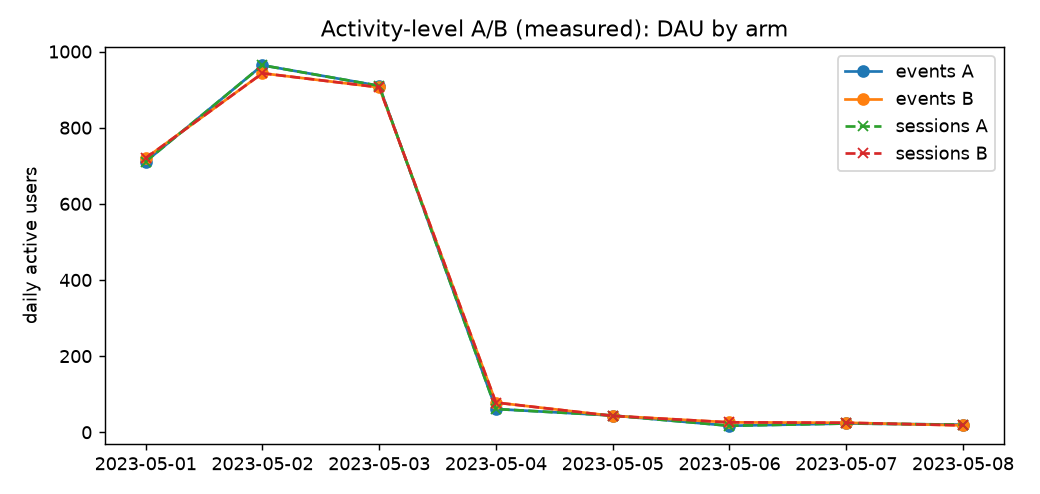

In [2]:
bal = pd.DataFrame(business["clickstream_ab"]["balance"])
per_user = pd.DataFrame(business["clickstream_ab"]["per_user"])
display(bal)
display(per_user.round(4))

print("SRM p-value:", bal["srm_p_value"].iloc[0])

display(Image(filename=str(FIGURES / "ab_activity.png")))

*Figure caption:* daily active users by arm, from `events` and `sessions`. This is a **volume-level** view. Because `events` has no event taxonomy, it can only say whether activity volume differs between arms — it is **not** funnel conversion.

## 3. Orders & ancillary — service mix, refunds, booking depth, price

`orders_metrics` (`src/business.py`) summarises the orders island. Most orders carry **no service label** (~79%); among labelled ones, `notification` and `changes` dominate. The refund rate is **~2.8%**. Ancillary economics are thin: `service_profit` has **median 0** and is labelled on only **~21%** of orders, so any profit read here is a lower bound.

,service,count,share
0,(none),7121,0.7942
1,notification,1082,0.1207
2,changes,485,0.0541
3,refund,255,0.0284
4,support,23,0.0026


refund rate: 2.84%


,order_platform,count,share
0,desktop,3399,0.3791
1,ios,2684,0.2994
2,android,1380,0.1539
3,ios_web,571,0.0637
4,android_web,500,0.0558
5,(none),412,0.0460
6,other,20,0.0022


price medians (order / service / service_profit): [{'order_price_50%': 15377.120468417303, 'service_price_50%': 499.0, 'service_profit_50%': 0.0}]
service_profit median=0.0 (~0); service labelled on 21% of orders


**Booking-depth distribution (binned)**

,bin_left,bin_right,count
0,-33.97,0.43,346
1,0.43,34.83,7674
2,34.83,69.22,627
3,69.22,103.62,160
4,103.62,138.02,75
5,138.02,172.41,49
6,172.41,206.81,27
7,206.81,241.21,7
8,241.21,275.60,0
9,275.60,310.00,1


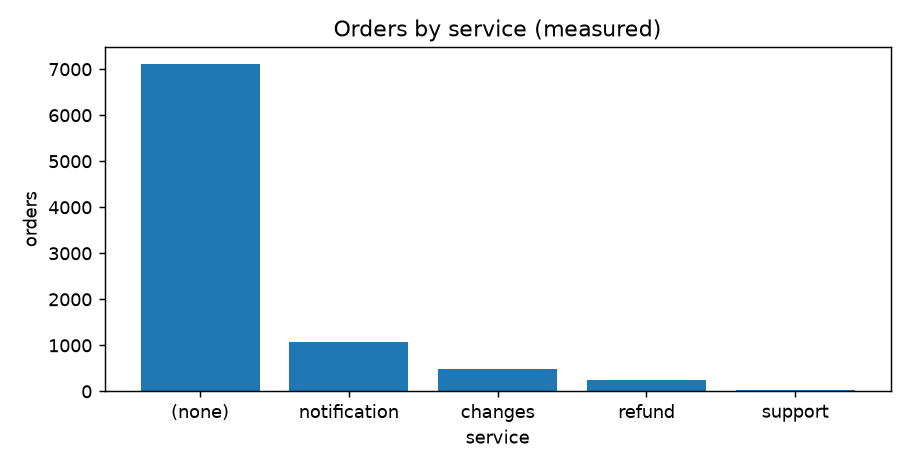

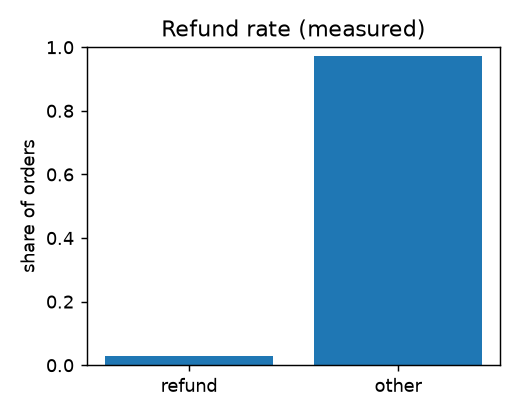

In [3]:
service_mix = pd.DataFrame(business["orders"]["service_mix"])
platform_mix = pd.DataFrame(business["orders"]["platform_mix"])
booking_depth = pd.DataFrame(business["orders"]["booking_depth"])
price_stats = pd.DataFrame(business["orders"]["price_stats"])

display(service_mix[["service", "count", "share"]].round(4))

refund_share = service_mix.loc[service_mix["service"] == "refund", "share"].iloc[0]
print(f"refund rate: {refund_share:.2%}")

display(platform_mix[["order_platform", "count", "share"]].round(4))

print("price medians (order / service / service_profit):",
      price_stats[["order_price_50%", "service_price_50%", "service_profit_50%"]].to_dict("records"))
print(price_stats["note"].iloc[0])

display(Markdown("**Booking-depth distribution (binned)**"))
display(booking_depth.round(2))

display(Image(filename=str(FIGURES / "orders_mix.png")))
display(Image(filename=str(FIGURES / "refund_rate.png")))

## 4. Supply & routes — airlines, LED concentration, seasonality

`routes_metrics` (`src/business.py`) summarises the bookings-legs island. Supply is concentrated: **DP ~29%**, then SU ~15% and FV ~14%. Routes are even more concentrated — **LED (St. Petersburg) is the destination of ~96% of legs**, and SVO/VKO/DME -> LED alone are ~93% of all legs. Connections are rare (~1.1%) and baggage is carried on ~14% of legs. Seasonality peaks in summer (May–Aug).

,airline,count,share
0,DP,40111,0.2926
1,SU,20984,0.1531
2,FV,19542,0.1426
3,5N,15328,0.1118
4,UT,8247,0.0602
5,U6,7942,0.0579
6,N4,7863,0.0574
7,S7,7464,0.0544


,origin,destination,count,share
0,SVO,LED,57836,0.4219
1,VKO,LED,51573,0.3762
2,DME,LED,18510,0.1350
3,SVO,HKT,2694,0.0197
4,(none),LED,1628,0.0119


connection share: 0.011   baggage share: 0.145


**Seasonality — legs by booking month (1-8)**

,booking_month,legs,share
0,1,13204,0.0963
1,2,10878,0.0794
2,3,12982,0.0947
3,4,14633,0.1067
4,5,20041,0.1462
5,6,22532,0.1644
6,7,21987,0.1604
7,8,20825,0.1519


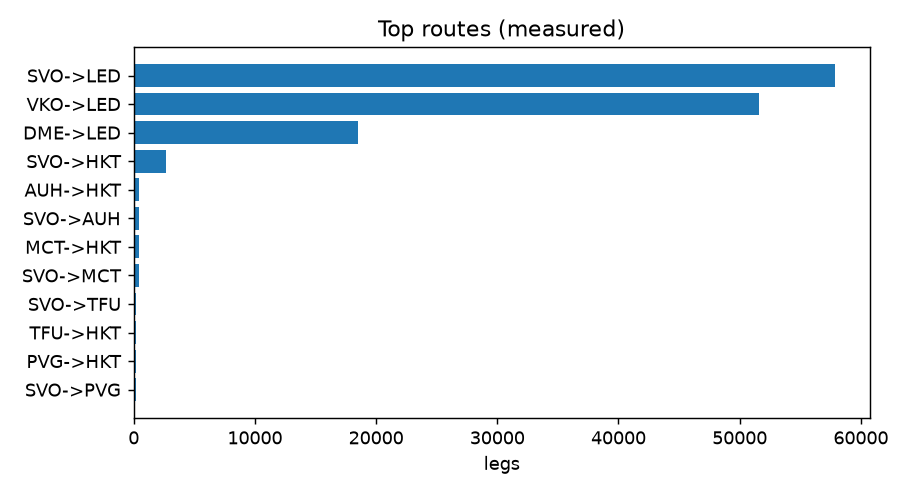

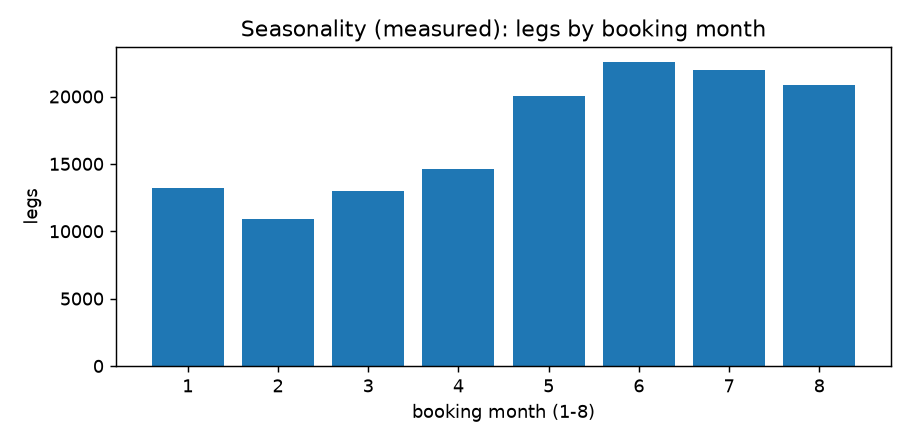

In [4]:
airlines = pd.DataFrame(business["routes"]["airlines"])
routes = pd.DataFrame(business["routes"]["routes"])
monthly = pd.DataFrame(business["routes"]["monthly"])

display(airlines.head(8)[["airline", "count", "share"]].round(4))
display(routes.head(5)[["origin", "destination", "count", "share"]].round(4))

print("connection share: %.3f   baggage share: %.3f" % (
    routes["connection_share"].iloc[0], routes["baggage_share"].iloc[0]))

display(Markdown("**Seasonality — legs by booking month (1-8)**"))
display(monthly.round(4))

display(Image(filename=str(FIGURES / "routes.png")))
display(Image(filename=str(FIGURES / "seasonality.png")))

## 5. Business conclusion

**Measured — islands, no fused funnel.** What an analyst would act on:

- **Route concentration is the top risk.** ~96% of legs land at LED, and SVO/VKO/DME -> LED is ~93% of volume. A supply or pricing shock on the Moscow -> St. Petersburg corridor dominates the whole feed; route diversification is the strategic lever.
- **Refunds are small but a real lever.** ~2.8% of orders are refunds; combined with thin ancillary labelling (~21% labelled, median profit 0), refund *drivers* cannot be modelled until services are better tagged.
- **Ancillary mix is an opportunity held back by data quality.** `notification` / `changes` are the labelled services; a median `service_profit` of 0 means the true ancillary margin is currently unmeasured, not zero.
- **The A/B is a volume check, not a conversion verdict.** With no event taxonomy, the clickstream can only report whether activity **volume** differs between arms — never whether a funnel converted.

Caveat restated: all of this is **measured**, but `orders` and `bookings_legs` are islands with no join key and no time overlap with the clickstream — **no unified funnel**, and the two blocks are never fused (`docs/adr/0001-modeled-vs-measured.md`).